# 01 · Frequentist analysis of the raw asymmetry $A_{\rm raw}$ in $B^\pm\to K^\pm K^+K^-$

**What this notebook is.** A guided tour of *how* the frequentist part of the study was done, step by step: from the
raw candidates of the LHCb Open Data to the value of $A_{\rm raw}$ with its uncertainty, its significance and its
systematic uncertainty. It follows the order of the report (`short`) and, in the last sections, the checks of its
appendix (`cut`).

**What it is not.** It is not the production run of the analysis. To keep the whole notebook under ~30 minutes the
expensive parts (bootstrap, toy experiments, scans) use *fewer* replicas and *coarser* grids than in the report, so
the numbers can differ slightly from it. Next to every result you find the value quoted in the report
(**report:**) to compare the two; the method is identical.

**The observable.**
$$A_{\rm raw}=\frac{N(B^-)-N(B^+)}{N(B^-)+N(B^+)}$$
measured on the signal yields of $B^\pm\to K^\pm K^+K^-$ decays. It is a *raw* asymmetry: it is not corrected for
production and detection asymmetries, so it is not a measurement of $A_{CP}$.

### Map of the notebook

| § | Content | Report (short → cut appendix) |
|---|---|---|
| 1 | Data, preselection, mass | *Data*; App. *Dataset and preselection* |
| 2 | Mass model and likelihood | *Mass model and likelihood* |
| 3 | Fit: separate and simultaneous, Minos intervals, goodness of fit | *Frequentist analysis* |
| 4 | Profile likelihood, Wilks test of $A=0$ | *Frequentist analysis* |
| 5 | Coverage with a bootstrap of the data | *Frequentist analysis* |
| 6 | Toy experiments: bias, pulls, coverage, size and power, Neyman belt | *Validation of the estimator* |
| 7 | Systematic uncertainty: 13 variants and the combination rule | *Result and systematics* |
| 8 | Stability scans and fine scan of the PID cut | App. *Systematics* |
| 9 | Local asymmetry in the Dalitz plane, charm vetoes, region of the published analysis | *Dalitz plane* |
| 10 | Summary | *Introduction*, Table 1 |

Parts that go beyond the techniques of the course are tagged **[EXTRA]**.

## 0 · Setup

In [1]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from scipy.stats import norm, chi2
from iminuit import Minuit, cost

import plot_style
plot_style.use()
C = plot_style.COLORS
T0 = time.time()

# Data: put the three .root files of CERN Open Data record 4900 in ./data (or edit the path)
DATA_DIR = "data" if os.path.isdir("data") else "../../opendata-project/Data"
np.random.seed(1)

M_K = 493.677            # charged-kaon mass [MeV]
LO, HI = 5100.0, 5600.0  # nominal fit window of the mass [MeV]

## 1 · Data and preselection

The record contains $B^\pm\to h^\pm h^+h^-$ candidates (2011 data, 7 TeV), one file per magnet polarity. Every
candidate has the momentum, the particle-identification (PID) likelihoods and the charge of the three tracks
$H_1,H_2,H_3$. We read only the branches we need.

In [2]:
tracks = (1, 2, 3)
branches = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge")]

frames = []
for pol in ("Down", "Up"):
    with uproot.open(f"{DATA_DIR}/B2HHH_Magnet{pol}.root") as f:
        d = f["DecayTree"].arrays(branches, library="pd")
    d["magnet"] = pol.lower()
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
print("candidates in the record:", len(df))

candidates in the record: 8556118


**Preselection.** We want $B^\pm\to K^\pm K^+K^-$: all three tracks must look like kaons and not like pions or muons,

$$\texttt{ProbPi}<0.5\ \wedge\ \texttt{ProbK}>0.5\ \wedge\ \lnot\texttt{isMuon}\quad\text{for each of the three tracks.}$$

The cut flow below gives the effect of each requirement alone and cumulatively (cut appendix, Table 1).

In [3]:
not_muon = np.ones(len(df), bool); pi_ok = np.ones(len(df), bool); k_ok = np.ones(len(df), bool)
for i in tracks:
    not_muon &= ~df[f"H{i}_isMuon"].to_numpy().astype(bool)
    pi_ok    &= df[f"H{i}_ProbPi"].to_numpy() < 0.5
    k_ok     &= df[f"H{i}_ProbK"].to_numpy() > 0.5

print(f"{'requirement':28s} {'alone':>10s} {'cumulative':>11s}")
cum = np.ones(len(df), bool)
for name, mask in (("not muon (3 tracks)", not_muon), ("ProbPi < 0.5 (3 tracks)", pi_ok), ("ProbK > 0.5 (3 tracks)", k_ok)):
    cum &= mask
    print(f"{name:28s} {mask.sum():10d} {cum.sum():11d}")
print("report: 6311517 / 975724 / 28812 alone, 23895 cumulative")

requirement                       alone  cumulative
not muon (3 tracks)             6311517     6311517
ProbPi < 0.5 (3 tracks)          975724      481101
ProbK > 0.5 (3 tracks)            28812       23895
report: 6311517 / 975724 / 28812 alone, 23895 cumulative


**Invariant mass.** We give the kaon mass to the three tracks, sum the four-momenta and take $m^2=E^2-|\vec p|^2$.
The two opposite-sign pairs $m(H_1H_2)$ and $m(H_1H_3)$ are kept for the Dalitz plane ($H_1$ is always the kaon with
charge opposite to the $B$).

We keep a slightly looser sample (`ProbK > 0.3`, `ProbPi < 0.7`) and store the *weakest* PID value of each
candidate: later the systematic study and the PID scan simply re-apply tighter cuts on these columns.

In [4]:
loose = np.ones(len(df), bool)
for i in tracks:
    loose &= (df[f"H{i}_ProbK"] > 0.3) & (df[f"H{i}_ProbPi"] < 0.7) & ~df[f"H{i}_isMuon"].astype(bool)
d = df[loose].reset_index(drop=True)
del df

def invariant_mass(d, particles):
    """Invariant mass [MeV] of the listed tracks, kaon mass hypothesis."""
    E = sum(np.sqrt(d[f"H{i}_PX"]**2 + d[f"H{i}_PY"]**2 + d[f"H{i}_PZ"]**2 + M_K**2) for i in particles)
    px, py, pz = (sum(d[f"H{i}_{c}"] for i in particles) for c in ("PX", "PY", "PZ"))
    return np.sqrt(np.clip(E**2 - px**2 - py**2 - pz**2, 0, None))

d["m"]  = invariant_mass(d, (1, 2, 3))
d["m12"], d["m13"] = invariant_mass(d, (1, 2)), invariant_mass(d, (1, 3))
d["q"]  = d.H1_Charge + d.H2_Charge + d.H3_Charge              # charge of the B
d["pT"] = np.sqrt(sum(d[f"H{i}_PX"] for i in tracks)**2 + sum(d[f"H{i}_PY"] for i in tracks)**2)
d["p"]  = np.sqrt(d.pT**2 + sum(d[f"H{i}_PZ"] for i in tracks)**2)
d["min_probk"]  = d[[f"H{i}_ProbK" for i in tracks]].min(axis=1)
d["max_probpi"] = d[[f"H{i}_ProbPi" for i in tracks]].max(axis=1)
d = d[np.abs(d.q) == 1]
assert (d.H1_Charge == -d.q).all()          # H1 has the opposite charge of the B

nominal = d[(d.min_probk > 0.5) & (d.max_probpi < 0.5)]
sample = nominal[(nominal.m > LO) & (nominal.m < HI)].reset_index(drop=True)
print(f"preselected: {len(nominal)} (report 23895);  in the window [{LO:.0f},{HI:.0f}]: {len(sample)} (report 19731)")
m_pos = sample.m[sample.q > 0].to_numpy()       # B+
m_neg = sample.m[sample.q < 0].to_numpy()       # B-
n_pos, n_neg = len(m_pos), len(m_neg)

preselected: 23895 (report 23895);  in the window [5100,5600]: 19731 (report 19731)


**A first number: counting.** Without any fit, the asymmetry of *all* candidates (signal and background together) is
$A_{\rm count}=(N^--N^+)/(N^-+N^+)$ with binomial uncertainty $\sqrt{(1-A^2)/N}$.

N(B+) = 10292, N(B-) = 9439;  A_count = -0.0432 +- 0.0071   (report: -0.0432 +- 0.0071)


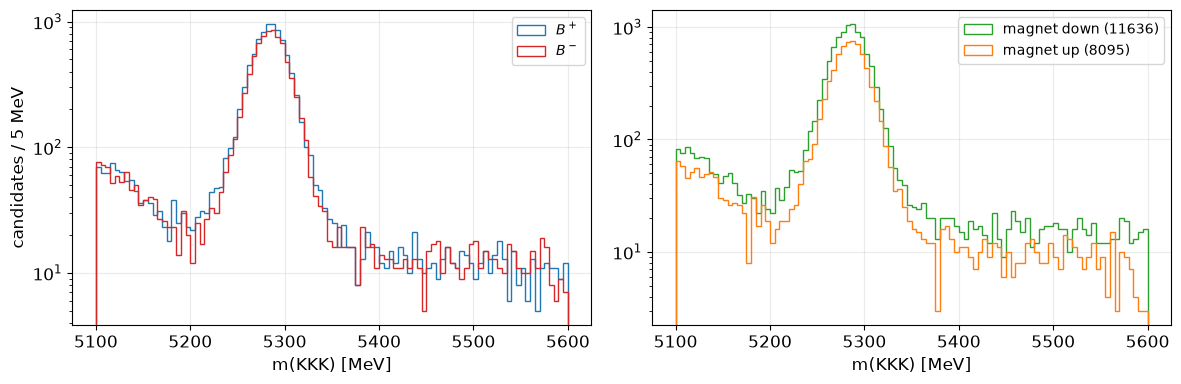

In [5]:
def count_asym(q):
    n = len(q); a = (np.sum(q < 0) - np.sum(q > 0)) / n
    return a, np.sqrt((1 - a**2) / n)

a_c, da_c = count_asym(sample.q.to_numpy())
print(f"N(B+) = {n_pos}, N(B-) = {n_neg};  A_count = {a_c:+.4f} +- {da_c:.4f}   (report: -0.0432 +- 0.0071)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.arange(LO, HI + 1, 5)
ax[0].hist(m_pos, bins, histtype="step", color=C["pos"], label="$B^+$")
ax[0].hist(m_neg, bins, histtype="step", color=C["neg"], label="$B^-$")
ax[0].set(yscale="log", xlabel="m(KKK) [MeV]", ylabel="candidates / 5 MeV"); ax[0].legend()
for pol in ("down", "up"):
    s = sample[sample.magnet == pol]
    ax[1].hist(s.m, bins, histtype="step", color=C[pol], label=f"magnet {pol} ({len(s)})")
ax[1].set(yscale="log", xlabel="m(KKK) [MeV]"); ax[1].legend()
plt.tight_layout(); plt.show()

The peak at $m\approx5284$ MeV over a falling background has the same shape for the two charges and the two
polarities: this allows a mass $\mu$ and a resolution $\sigma$ *common* to $B^+$ and $B^-$ in the model.

## 2 · Mass model and likelihood

For each charge the mass spectrum is a mixture of signal and background on the window $[5100,5600]$ MeV,

$$f^\pm(m)=N_s^\pm\,S(m;\mu,\sigma)+N_b^\pm\,B^\pm(m),\qquad
N_s^\pm=\tfrac{N_s}{2}(1\mp A),$$

* **signal** $S$: Gaussian, truncated and normalised to the window; $\mu,\sigma$ are *shared* by $B^+$ and $B^-$;
* **background** $B^\pm$: sum of two exponentials, $f\,E(\lambda_1)+(1-f)\,E(\lambda_2)$, with a shape and a yield of
  its own for each charge (the steep exponential describes the rise of the background towards the lower edge);
* **$A$** is a parameter of the fit: it is the *parameter of interest* (POI); the other 11 are *nuisance parameters*.

The likelihood is *extended* (the yields are parameters, the number of candidates is Poisson):

$$-\ln\mathcal L=(N_s+N_b)-\sum_{\pm}\sum_{i\in\pm}\ln\!\big[N_s^\pm S(m_i)+N_b^\pm B^\pm(m_i)\big]+\text{const.}$$

We write the pdfs ourselves (a few lines each) and let `iminuit` build the extended likelihood with
`cost.ExtendedUnbinnedNLL`: the model is a function `model(m, *parameters)` that returns the expected total number
of events and the density of events at $m$.

In [6]:
def gauss_pdf(m, mu, sigma, lo=LO, hi=HI):
    """Gaussian normalised on [lo, hi]."""
    return norm.pdf(m, mu, sigma) / (norm.cdf(hi, mu, sigma) - norm.cdf(lo, mu, sigma))

def exp_pdf(m, lam, lo=LO, hi=HI):
    """Decreasing exponential exp(-lam (m - lo)) normalised on [lo, hi]."""
    return lam * np.exp(-lam * (m - lo)) / (1 - np.exp(-lam * (hi - lo)))

def bkg_pdf(m, lam1, lam2, f, lo=LO, hi=HI):
    """Background: two exponentials, weight f on the steep one (lam1 > lam2)."""
    return f * exp_pdf(m, lam1, lo, hi) + (1 - f) * exp_pdf(m, lam2, lo, hi)

# one model per charge; the parameters with the same name (N_s, A, mu, sigma) are shared in the joint fit
def model_pos(m, N_s, A, mu, sigma, N_b_pos, lam1_pos, lam2_pos, f_pos):
    n_sig = N_s * (1 - A) / 2                       # B+ : (1 - A) / 2
    return n_sig + N_b_pos, n_sig * gauss_pdf(m, mu, sigma) + N_b_pos * bkg_pdf(m, lam1_pos, lam2_pos, f_pos)

def model_neg(m, N_s, A, mu, sigma, N_b_neg, lam1_neg, lam2_neg, f_neg):
    n_sig = N_s * (1 + A) / 2                       # B- : (1 + A) / 2
    return n_sig + N_b_neg, n_sig * gauss_pdf(m, mu, sigma) + N_b_neg * bkg_pdf(m, lam1_neg, lam2_neg, f_neg)

## 3 · The fit

### 3.1 Separate fits (a cross-check)

First each charge is fitted alone (seven free parameters: yields, $\mu$, $\sigma$, background shape) and the
asymmetry is computed from the two signal yields, $A=(N_s^--N_s^+)/(N_s^-+N_s^+)$, propagating the uncertainties.

In [7]:
def model_single(m, N_s, mu, sigma, N_b, lam1, lam2, f):
    return N_s + N_b, N_s * gauss_pdf(m, mu, sigma) + N_b * bkg_pdf(m, lam1, lam2, f)

def fit_single(m_data):
    nll = cost.ExtendedUnbinnedNLL(m_data, model_single)
    fit = Minuit(nll, N_s=0.78 * len(m_data), mu=5284.0, sigma=18.0, N_b=0.22 * len(m_data), lam1=0.03, lam2=0.002, f=0.15)
    fit.limits["mu"] = (5260, 5310); fit.limits["sigma"] = (3, 40)
    fit.limits["lam1"] = (1e-5, 0.1); fit.limits["lam2"] = (1e-5, 0.1); fit.limits["f"] = (0, 1)
    fit.limits["N_s"] = (0, 2 * len(m_data)); fit.limits["N_b"] = (0, 2 * len(m_data))
    fit.migrad(); fit.hesse()
    return fit

fit_p, fit_n = fit_single(m_pos), fit_single(m_neg)
Np, dNp = fit_p.values["N_s"], fit_p.errors["N_s"]
Nn, dNn = fit_n.values["N_s"], fit_n.errors["N_s"]
A_sep = (Nn - Np) / (Nn + Np)
dA_sep = 2 * np.sqrt((Np * dNn)**2 + (Nn * dNp)**2) / (Nn + Np)**2
print(f"valid: {fit_p.valid}, {fit_n.valid};  N_s(B+) = {Np:.0f} +- {dNp:.0f},  N_s(B-) = {Nn:.0f} +- {dNn:.0f}")
print(f"A_raw (separate fits) = {A_sep:+.4f} +- {dA_sep:.4f}     (report: -0.0442 +- 0.0087)")

valid: True, True;  N_s(B+) = 8003 +- 96,  N_s(B-) = 7325 +- 92
A_raw (separate fits) = -0.0442 +- 0.0086     (report: -0.0442 +- 0.0087)


### 3.2 Simultaneous fit: the nominal result

The two charges are fitted *together*: the total cost is the sum of the two extended likelihoods and $A$ is a
parameter of it, so the profile likelihood of $A$ is available directly. `Migrad` minimises, `Hesse` gives the
symmetric uncertainties from the curvature (inverse of the Fisher information) and `Minos` the asymmetric
intervals from the profile likelihood.

In [8]:
nll = cost.ExtendedUnbinnedNLL(m_pos, model_pos) + cost.ExtendedUnbinnedNLL(m_neg, model_neg)
start = dict(N_s=0.78 * len(sample), A=-0.04, mu=5284.0, sigma=18.0,
             N_b_pos=0.22 * n_pos, lam1_pos=0.03, lam2_pos=0.002, f_pos=0.15,
             N_b_neg=0.22 * n_neg, lam1_neg=0.03, lam2_neg=0.002, f_neg=0.15)
fit = Minuit(nll, **start)
fit.limits["A"] = (-1, 1); fit.limits["mu"] = (5260, 5310); fit.limits["sigma"] = (3, 40)
for s in ("pos", "neg"):
    fit.limits[f"lam1_{s}"] = (1e-5, 0.1); fit.limits[f"lam2_{s}"] = (1e-5, 0.1); fit.limits[f"f_{s}"] = (0, 1)
fit.migrad(); fit.hesse()
fit.minos("A")                                      # 68 % interval (default cl = 1 sigma)
ci68 = (fit.values["A"] + fit.merrors["A"].lower, fit.values["A"] + fit.merrors["A"].upper)
fit_95 = copy.deepcopy(fit); fit_95.minos("A", cl=0.95)
ci95 = (fit_95.values["A"] + fit_95.merrors["A"].lower, fit_95.values["A"] + fit_95.merrors["A"].upper)

assert fit.valid and fit.values["lam1_pos"] > fit.values["lam2_pos"] and fit.values["lam1_neg"] > fit.values["lam2_neg"]
for k in ("N_s", "A", "mu", "sigma"):
    print(f"{k:8s} = {fit.values[k]:12.4f} +- {fit.errors[k]:.4f}")
print(f"N_b = {fit.values['N_b_pos'] + fit.values['N_b_neg']:.0f}")
print(f"\nA_raw = {fit.values['A']:+.4f} +- {fit.errors['A']:.4f} (Hesse)")
print(f"  68% Minos [{ci68[0]:+.4f}, {ci68[1]:+.4f}]    report: [-0.0526, -0.0356]")
print(f"  95% Minos [{ci95[0]:+.4f}, {ci95[1]:+.4f}]    report: [-0.0607, -0.0275]")
print("report: A = -0.0441 +- 0.0085, N_s = 15328 +- 133")

N_s      =   15329.1889 +- 132.9308
A        =      -0.0441 +- 0.0085
mu       =    5284.3783 +- 0.1591
sigma    =      18.0026 +- 0.1407
N_b = 4402

A_raw = -0.0441 +- 0.0085 (Hesse)
  68% Minos [-0.0526, -0.0356]    report: [-0.0526, -0.0356]
  95% Minos [-0.0607, -0.0275]    report: [-0.0607, -0.0275]
report: A = -0.0441 +- 0.0085, N_s = 15328 +- 133


### 3.3 Goodness of fit and picture

The $\chi^2=\sum_i(n_i-\nu_i)^2/\nu_i$ in bins of 10 MeV (both charges, $\nu_i$ from the fitted model) with
$\mathrm{ndof}=2\times50-12$. The pulls $(n_i-\nu_i)/\sqrt{\nu_i}$ show *where* the model fails. (The model is not
perfect: the signal tails are heavier than a Gaussian; $A_{\rm raw}$ does not depend on it, see §7.)

chi2/ndof = 159.5/88,  p = 4.8e-06     (report: 160/88, p = 4.8e-6)


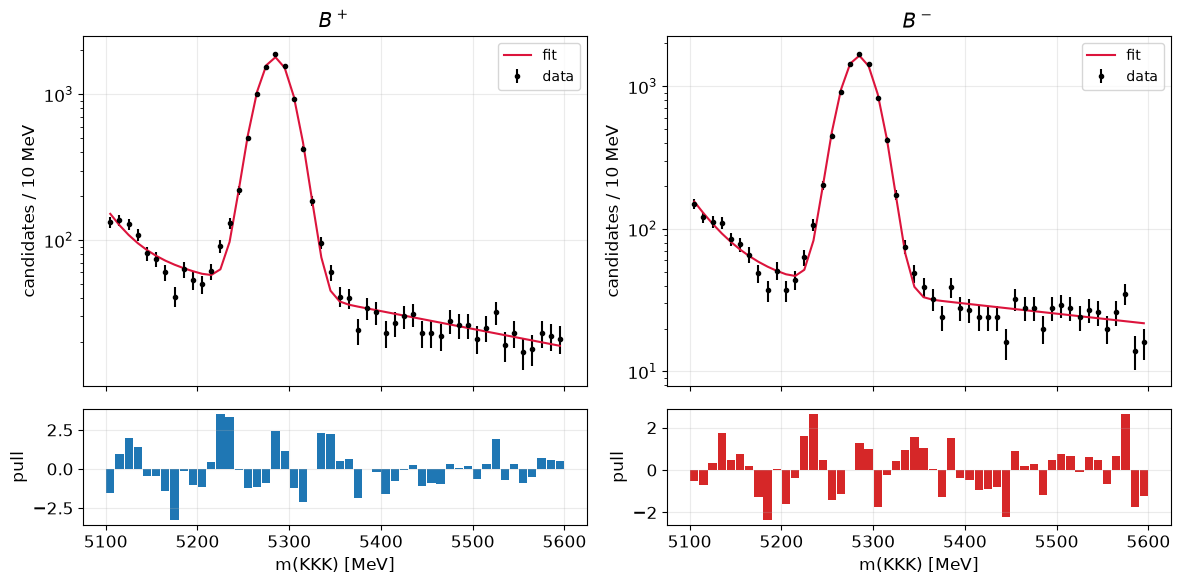

In [9]:
def expected_counts(model, args, edges, n_sub=5):
    """Expected counts per bin: mean of the density at n_sub points in each bin, times the width."""
    width = edges[1] - edges[0]
    offs = (np.arange(n_sub) + 0.5) / n_sub
    pts = edges[:-1, None] + offs[None, :] * width
    return model(pts, *args)[1].mean(axis=1) * width

edges = np.arange(LO, HI + 1e-9, 10.0)
centers = 0.5 * (edges[1:] + edges[:-1])
v = fit.values
nu_pos = expected_counts(model_pos, [v[k] for k in ("N_s", "A", "mu", "sigma", "N_b_pos", "lam1_pos", "lam2_pos", "f_pos")], edges)
nu_neg = expected_counts(model_neg, [v[k] for k in ("N_s", "A", "mu", "sigma", "N_b_neg", "lam1_neg", "lam2_neg", "f_neg")], edges)
obs_pos, obs_neg = np.histogram(m_pos, edges)[0], np.histogram(m_neg, edges)[0]
chi2_val = np.sum((obs_pos - nu_pos)**2 / nu_pos) + np.sum((obs_neg - nu_neg)**2 / nu_neg)
ndof = 2 * len(centers) - 12
print(f"chi2/ndof = {chi2_val:.1f}/{ndof},  p = {chi2.sf(chi2_val, ndof):.1e}     (report: 160/88, p = 4.8e-6)")

fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for col, (obs, nu, lab, c) in enumerate(((obs_pos, nu_pos, "$B^+$", C["pos"]), (obs_neg, nu_neg, "$B^-$", C["neg"]))):
    ax[0, col].errorbar(centers, obs, np.sqrt(obs), fmt="o", ms=3, color="k", label="data")
    ax[0, col].plot(centers, nu, color=C["model"], label="fit")
    ax[0, col].set(yscale="log", ylabel="candidates / 10 MeV", title=lab); ax[0, col].legend()
    ax[1, col].bar(centers, (obs - nu) / np.sqrt(nu), width=9, color=c)
    ax[1, col].set(xlabel="m(KKK) [MeV]", ylabel="pull")
plt.tight_layout(); plt.show()

## 4 · Profile likelihood and test of $A=0$

The **profile likelihood ratio** re-minimises the 11 nuisance parameters at each value of $A$,
$$q(A)=-2\ln\frac{\mathcal L(A,\hat{\hat\theta}(A))}{\mathcal L(\hat A,\hat\theta)} .$$
By Wilks' theorem $q(A_{\rm true})\sim\chi^2_1$, so the 68 % and 95 % intervals are the sets $q\le1$ and $q\le3.84$
(the Minos intervals above). The null hypothesis $H_0:A=0$ is tested with $q(0)$: $p=P(\chi^2_1>q(0))$ and the
significance is $Z=\sqrt{q(0)}$.

q(0) = 54.0,  p = 2.03e-13,  Z = sqrt(q) = 7.35 sigma     (report: q ~ 27, p = 2.05e-7, 5.20 sigma)


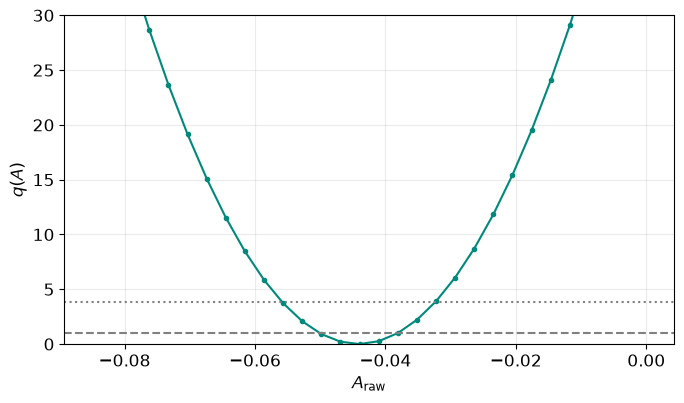

In [10]:
def q_at(A0, best=fit):
    """Profile likelihood ratio at A = A0: fix A, re-minimise everything else."""
    f0 = copy.deepcopy(best)
    f0.values["A"] = A0
    f0.fixed["A"] = True
    f0.migrad()
    return 2 * (f0.fval - best.fval)

q0 = q_at(0.0)
print(f"q(0) = {q0:.1f},  p = {chi2.sf(q0, 1):.2e},  Z = sqrt(q) = {np.sqrt(q0):.2f} sigma     (report: q ~ 27, p = 2.05e-7, 5.20 sigma)")

a_grid, q_grid, _ = fit.mnprofile("A", size=30, bound=(-0.085, 0.0))
q_grid = 2 * (q_grid - fit.fval)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(a_grid, q_grid, "o-", color=C["freq"], ms=3)
ax.axhline(1, ls="--", color="gray"); ax.axhline(3.84, ls=":", color="gray")
ax.set(xlabel="$A_{\\rm raw}$", ylabel="$q(A)$", ylim=(0, 30))
plt.tight_layout(); plt.show()